# 1. Problem

Recover a stationary spatial illumination field and 100 changing background levels from a real stem-cell brightfield time series. Moving biological objects contaminate the images, while a fixed gain pattern remains at the sensor. The scale is ambiguous until the flatfield is normalized to mean one.

This notebook actively executes the complete selected modern BaSiCPy approximate method through locally implemented mathematics: all automatic-selection candidates and the final 100-frame fit. The 2017 paper supplies the model motivation; the modern Torch implementation is the exact selected source method. No independent measured flatfield truth is available. Original method outputs are labeled **reproduced original**, never ground truth.

In [1]:
%matplotlib inline
from pathlib import Path
import sys,json,time,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.main import run
from src.preprocessing import load_observations,resize_stack
from src import visualization as viz
from src.physics_model import quality
images=load_observations(ROOT/'data/raw_data.npz')
print('Original observations:',images.shape,images.dtype,'DN')
print('Chronological frames: t05100 through t05199; no synthetic observations')


Original observations: (100, 1040, 1388) uint8 DN
Chronological frames: t05100 through t05199; no synthetic observations


# 2. Data

All 100 uncorrected author images are retained at native 1040×1388 resolution and uint8 precision. The following four examples span the sequence. Intensity is in digital numbers (DN); physical pixel spacing and acquisition interval were not supplied and are not invented.

The 128×128 model basis is a specified antialiased representation of the complete sensor field. It is not a crop, a selected quality mask, or a downsampled replacement of the stored measurements. Additive darkfield is fixed to zero as the selected conditional model assumption.

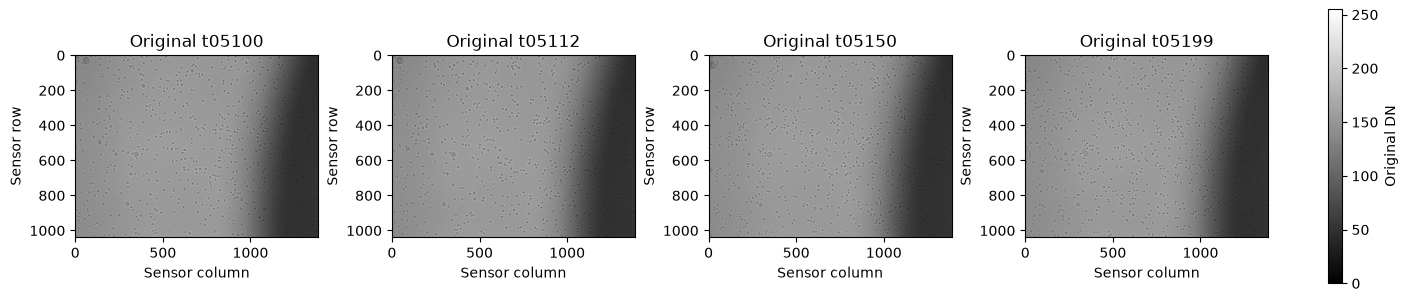

In [2]:
viz.image_grid(images,[0,12,50,99]);plt.show()


# 3. Physics and mathematical target

For frame index $t$ and sensor model pixel $p$, the DN observation is

$$I_{tp}=b_t S_p+R_{tp},\qquad S_p>0,\quad b_t>0,\quad \operatorname{mean}_p S_p=1.$$

The flatfield $S$ is dimensionless, the temporal background $b$ is in DN, and the residual $R$ includes biological structure and noise. A stationary biological structure cannot be perfectly distinguished from shading without additional assumptions. This benchmark therefore defines a conditional quality class rather than claiming recovery of a unique instrument truth.

Let $P=128^2$, $C$ be the orthonormal spatial type-II DCT, and $\overline b$ the mean temporal background. The fixed evaluation quantities are

$$A=\frac{1}{100P}\sum_{t,p}|I_{tp}-b_tS_p|,\qquad
J=A+\frac{5}{P}\left\|C(S\overline b)\right\|_1.$$

Both quantities have units DN. Every frame and every model pixel contributes. The constraints are $J\le10.09925304298181$ DN, $A\le1.6162489661058033$ DN, and absolute mean-one error at most $10^{-5}$. No hidden field identity, arbitrary seed, or subsequent output rescaling is required.

The model image resampling uses normalized triangles. For a native axis length $n$, $s=(n-1)/127$, output center $c_i=s(i+1/2)$, and input index $j$, the unnormalized weight is $\max(0,1-|j-c_i+1/2|/s)$; normalize over available input pixels. Rows and columns are treated separably, preserving constants with a float32 weighted summation error.

# 4. Method

The selected approximate inverse alternates cosine-coefficient shrinkage for the spatial field, shrinkage for the residual, and a temporal background update. With temporary background factors $B$, absolute field $F$, dual multiplier $Y$, positive penalty $\mu$, residual weights $W$, and $H=C(F)$, the illumination update is

$$H^+=\operatorname{shrink}\!\left(H+C(\operatorname{mean}_t[I-R-BF+Y/\mu]),\lambda/\mu\right).$$

Here shrinkage means $\operatorname{sign}(x)\max(|x|-a,0)$. The residual update thresholds $I-BF^++Y/\mu$ by $W/\mu$; positive temporal factors follow from background frame means. Constraint residuals update the dual multiplier. Reweighting favors separation of persistent background from moving structure.

The method retains the author's complete automatic parameter selection: a 50-frame preliminary series, a coarse search, a fine search, a baseline-only refit for every candidate, and the final fit on all 100 frames. Candidate scores combine corrected-image histogram entropy with a high-frequency illumination penalty. All 13 actual original groups appear below. The final adaptive weighted problem is distinct from the fixed unweighted quality functional $J$; no exact minimizer claim is made.

Budgets are 500 inner updates, up to 10 field reweightings, and 5 baseline-only reweightings. The selected source convergence criteria remain active. We do not replace automatic selection by a known fixed answer.

In [3]:
started=time.perf_counter()
fresh=run(ROOT)
print('Complete fresh inverse seconds:',fresh['seconds'])
print('Selected illumination penalty:',fresh['smoothness'])
print('Final reweighting history:',json.dumps(fresh['history'],indent=2))
source_search=json.loads((ROOT/'test/fixtures/upstream_search_costs.json').read_text(encoding='utf-8'))
source=np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False)
coarse=resize_stack(images,(128,128))
fresh_metrics=quality(coarse,fresh['flatfield'],fresh['baseline'])
source_metrics=quality(coarse,source['reconstruction'][0],source['baseline'][0])
spec=importlib.util.spec_from_file_location('independent_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(ROOT/'output/reconstruction.npz')
print(json.dumps(report,indent=2));assert report['passed']


FRESH_COMPLETE_SEARCH {"smoothness_flatfield": 0.01, "cost": 29.491458892822266, "entropy": 2.459702491760254, "fourier_fraction": 0.901058554649353, "entropy_vmin": 3.1748015880584717, "entropy_vmax": 96.82970428466797}
FRESH_COMPLETE_SEARCH {"smoothness_flatfield": 0.1, "cost": 20.23830795288086, "entropy": 2.4568629264831543, "fourier_fraction": 0.5927148461341858, "entropy_vmin": 3.171633005142212, "entropy_vmax": 96.82653045654297}
FRESH_COMPLETE_SEARCH {"smoothness_flatfield": 0.5, "cost": 4.9655303955078125, "entropy": 2.456812858581543, "fourier_fraction": 0.08362390846014023, "entropy_vmin": 3.181837558746338, "entropy_vmax": 96.83673858642578}
FRESH_COMPLETE_SEARCH {"smoothness_flatfield": 2.0, "cost": 2.7893435955047607, "entropy": 2.475520372390747, "fourier_fraction": 0.010460772551596165, "entropy_vmin": 3.2112159729003906, "entropy_vmax": 96.86611938476562}
FRESH_COMPLETE_SEARCH {"smoothness_flatfield": 8.0, "cost": 2.6639204025268555, "entropy": 2.660184383392334, "four

# 5. Results

The following costs compare the independently reproduced original Torch implementation on these exact observations with the fresh NumPy implementation. They are dimensionless selection diagnostics, not DN reconstruction errors. Candidate fields are shown for every evaluated group, including those with high-frequency artifacts. The complete selected search still chooses $\lambda=5$.

| Stage | λ | Original cost | Fresh cost | Absolute difference |
| --- | --- | --- | --- | --- |
| coarse | 0.01 | 29.49149513 | 29.49145889 | 3.62e-05 |
| coarse | 0.1 | 20.23834038 | 20.23830795 | 3.24e-05 |
| coarse | 0.5 | 4.96556854 | 4.96553040 | 3.81e-05 |
| coarse | 2 | 2.78937936 | 2.78934360 | 3.58e-05 |
| coarse | 8 | 2.66394281 | 2.66392040 | 2.24e-05 |
| coarse | 10 | 2.73884201 | 2.73881936 | 2.26e-05 |
| fine | 2.5 | 2.69033432 | 2.69029880 | 3.55e-05 |
| fine | 3 | 2.62343049 | 2.62339902 | 3.15e-05 |
| fine | 4 | 2.59588051 | 2.59584594 | 3.46e-05 |
| fine | 5 | 2.58841634 | 2.58838558 | 3.08e-05 |
| fine | 6 | 2.61475086 | 2.61472201 | 2.88e-05 |
| fine | 7 | 2.64243174 | 2.64240670 | 2.5e-05 |
| fine | 8 | 2.66394281 | 2.66392040 | 2.24e-05 |

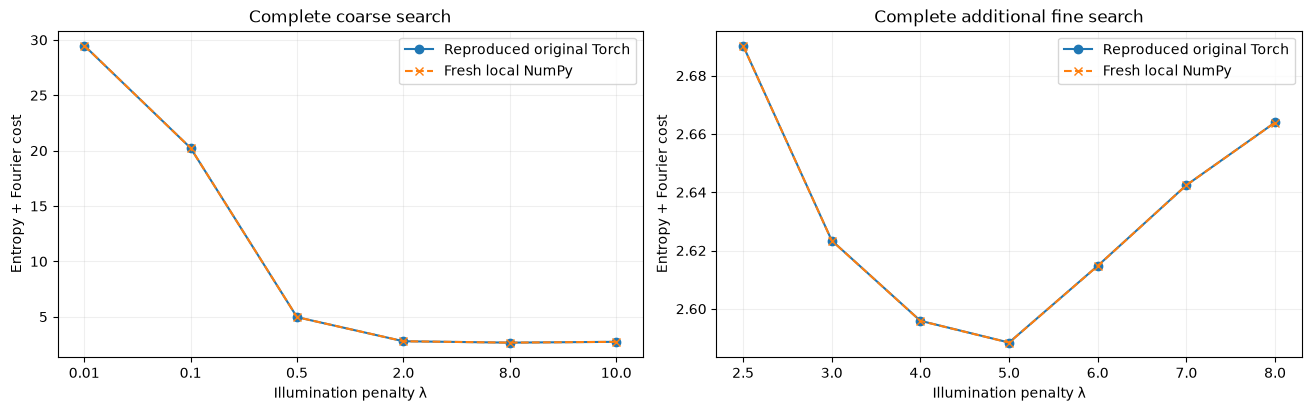

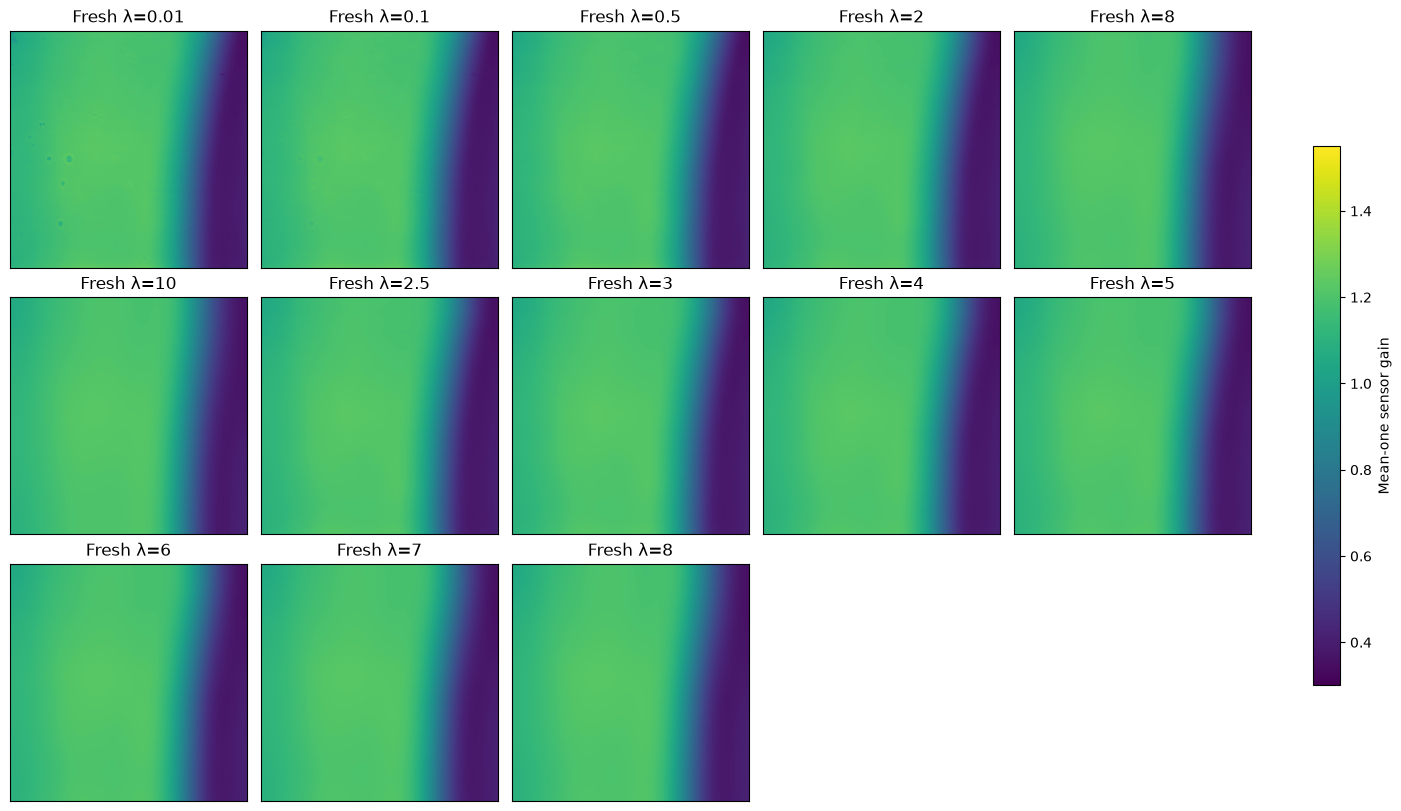

In [4]:
rows=['| Stage | λ | Original cost | Fresh cost | Absolute difference |','| --- | --- | --- | --- | --- |']
for i,(a,b) in enumerate(zip(fresh['search'],source_search)):
    rows.append(f"| {'coarse' if i<6 else 'fine'} | {a['smoothness_flatfield']:g} | {b['cost']:.8f} | {a['cost']:.8f} | {abs(a['cost']-b['cost']):.3g} |")
display(Markdown('\n'.join(rows)))
viz.search_comparison(fresh['search'],source_search);plt.show()
viz.search_fields(fresh['search_fields'],fresh['search']);plt.show()


The final mean-one field, all 100 temporal backgrounds and their differences are compared next. Numerical agreement validates extraction of the selected method; it does not turn either result into an independently measured flatfield. The reweighting trajectory is reported rather than hidden by a fixed-iteration description.

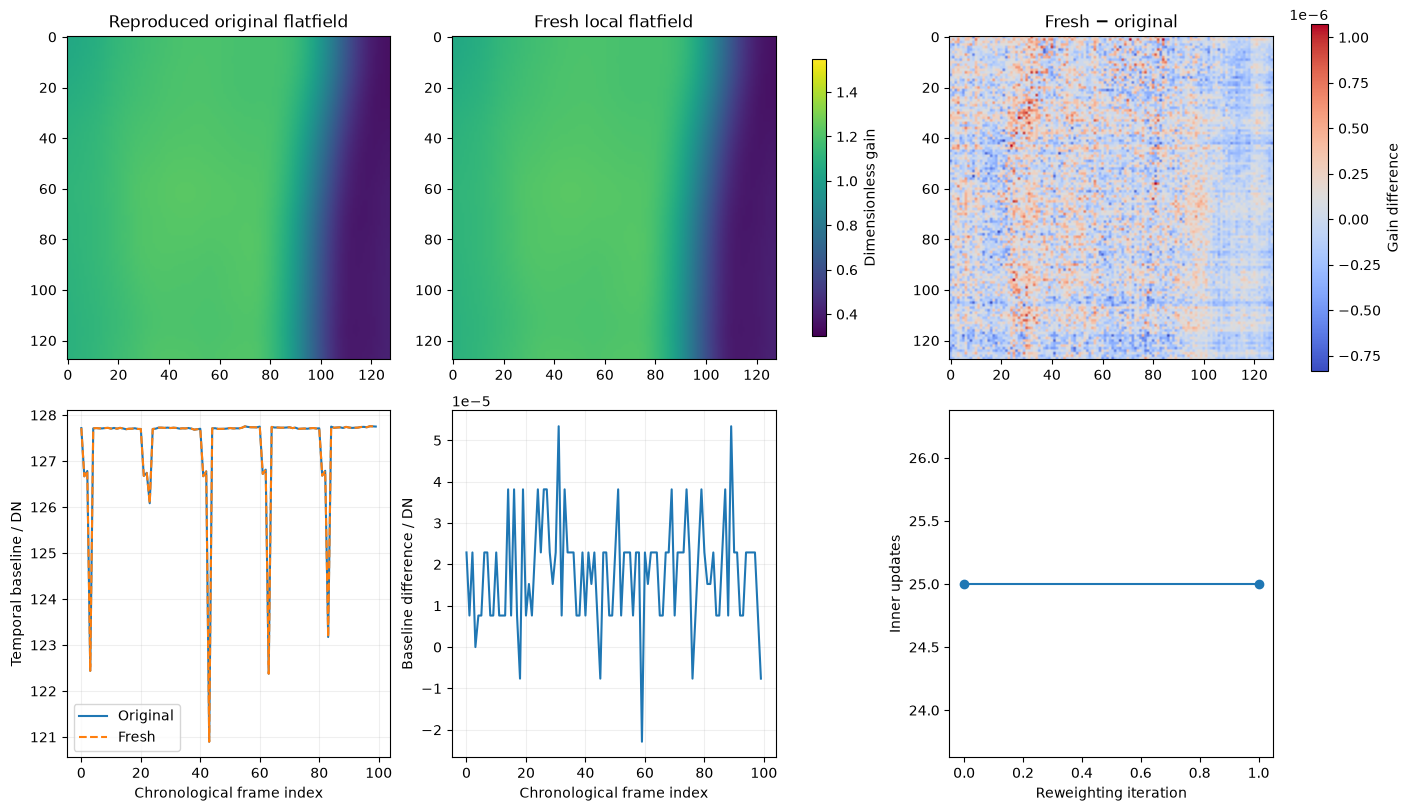

| Quantity | Reproduced original | Fresh local | Unit |
| --- | --- | --- | --- |
| objective_counts | 9.999260919 | 9.999302252 | DN |
| mean_abs_residual_counts | 1.469317722 | 1.469314876 | DN |
| flatfield_mean_abs_error | 1.475382305e-08 | 3.939931048e-08 | dimensionless |

Flatfield dynamic-range NRMSE: 2.7514125e-07
Temporal baseline RMS difference / DN: 2.2282535e-05


In [5]:
viz.recovered_fields(fresh,source);plt.show()
rows=['| Quantity | Reproduced original | Fresh local | Unit |','| --- | --- | --- | --- |']
for key in fresh_metrics:
    rows.append(f"| {key} | {source_metrics[key]:.10g} | {fresh_metrics[key]:.10g} | {'dimensionless' if 'mean_abs_error' in key else 'DN'} |")
display(Markdown('\n'.join(rows)))
print('Flatfield dynamic-range NRMSE:',np.sqrt(np.mean((fresh['flatfield']-source['reconstruction'][0])**2))/np.ptp(source['reconstruction']))
print('Temporal baseline RMS difference / DN:',np.sqrt(np.mean((fresh['baseline']-source['baseline'][0])**2)))


The author's final image transform is **gain-only correction**, image divided by the native-size interpolated flatfield. It does not subtract the temporal background. Its native examples and all-frame spatial mean/standard-deviation comparisons are preserved below. This differs from the baseline-subtracted transform used inside automatic selection; both roles are explicit.

Native transformed data are computed framewise from the fresh field, so the notebook does not allocate several full corrected stacks. A difference image shows extraction error, not error against biological truth. Shared grayscale scales permit direct comparison.

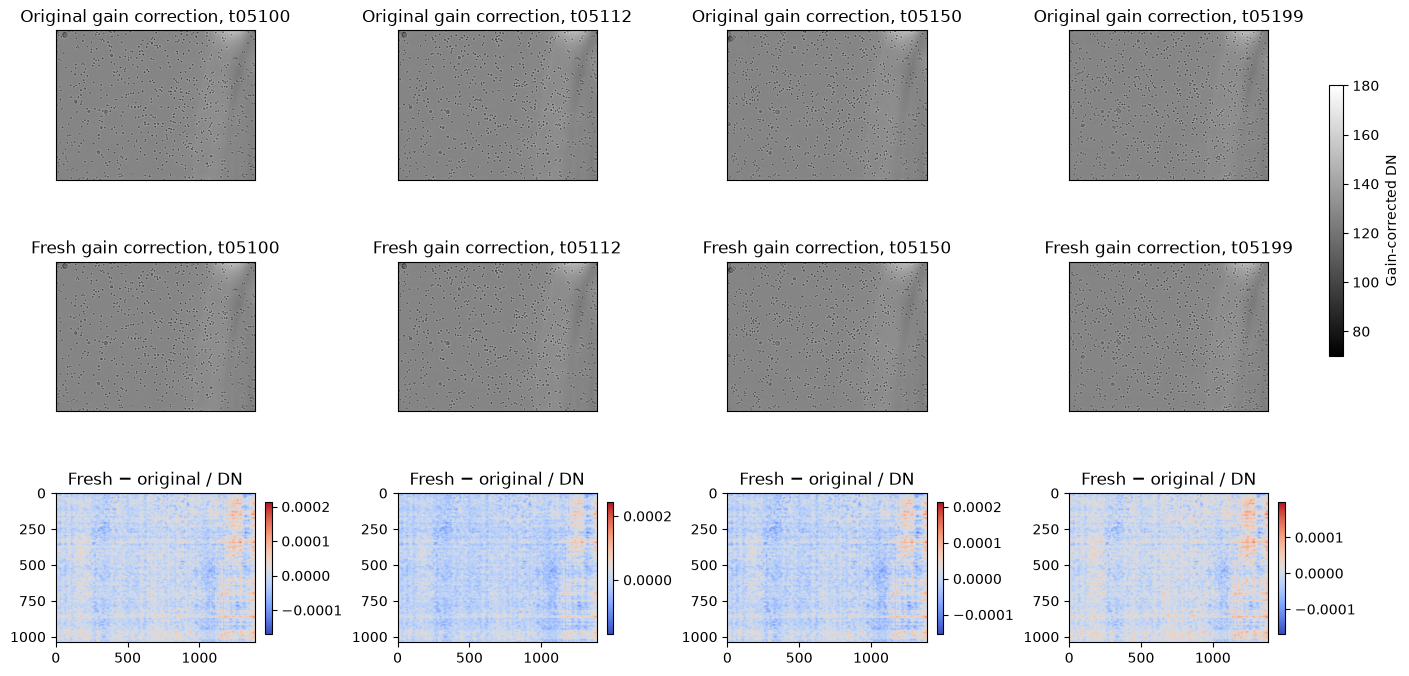

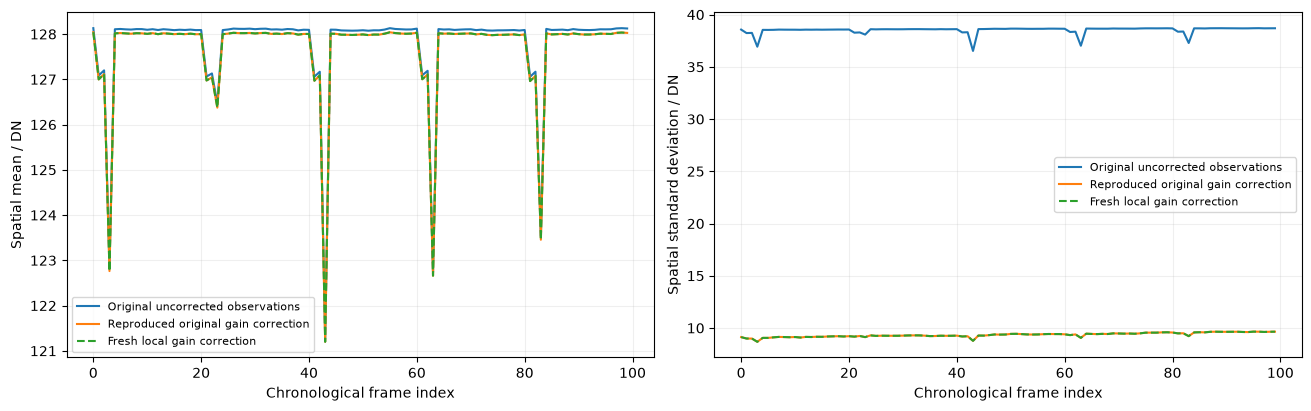

Native corrected examples maximum difference / DN: 0.00024414062
All100 corrected means maximum difference / DN: 6.866455078125e-05


In [6]:
native=viz.native_summary(images,fresh['flatfield'])
original_native=np.load(ROOT/'notebooks/reference_outputs/source_selected_views.npz',allow_pickle=False)
viz.correction_examples(native,original_native);plt.show()
viz.temporal_comparison(images,native,original_native);plt.show()
print('Native corrected examples maximum difference / DN:',np.max(abs(native['corrected']-original_native['corrected'])))
print('All100 corrected means maximum difference / DN:',np.max(abs(native['mean_by_frame']-original_native['mean_by_frame'])))


Both output quantities matter. The following controls retain the same observed data: unit gain, a constant temporal background, and reversed time order. Joint $J$ and $A$ thresholds prevent accepting a visually smooth field that omits the measured temporal behavior. These controls diagnose the acceptance boundary; they are not additional reconstruction methods or invented measurements.

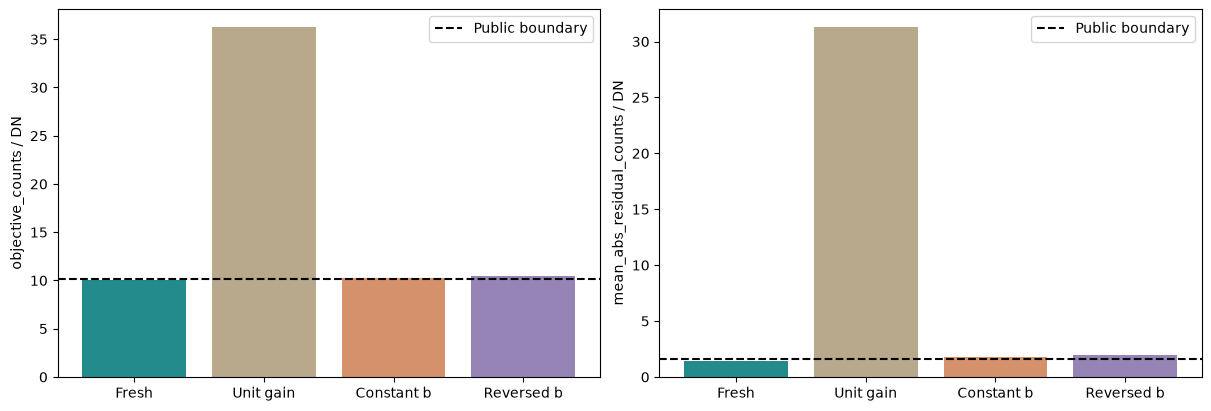

[
  {
    "objective_counts": 9.99930225241827,
    "mean_abs_residual_counts": 1.4693148759674448,
    "flatfield_mean_abs_error": 3.939931048080325e-08
  },
  {
    "objective_counts": 36.2827900399128,
    "mean_abs_residual_counts": 31.31367327167187,
    "flatfield_mean_abs_error": 0.0
  },
  {
    "objective_counts": 10.28876905286906,
    "mean_abs_residual_counts": 1.7587819420791118,
    "flatfield_mean_abs_error": 3.939931048080325e-08
  },
  {
    "objective_counts": 10.462793843641617,
    "mean_abs_residual_counts": 1.9328064671907919,
    "flatfield_mean_abs_error": 3.939931048080325e-08
  }
]


In [7]:
figure,controls=viz.quality_controls(coarse,fresh);plt.show()
print(json.dumps(controls,indent=2))


# 6. Conclusion

The complete selected automatic-selection and reweighted inverse has been executed on all real observations. It recovers a stationary gain field and temporal backgrounds that meet the jointly defined public quality criteria and agrees with the independently executed original implementation at justified finite-precision tolerances.

The zero-darkfield assumption, finite model grid, motion-dependent separation and lack of independently measured flatfield truth limit the interpretation. Corrected images are standard-method outputs, not a claim of exact biological radiometry. The notebook preserves original candidate groups and gain-correction comparisons while explicitly separating solver parity from physical accuracy.